# GRU-MLP hybrid comparison for ROEST thesis

**Purpose:** Compare the existing *tuned Hybrid LSTM-MLP* with a *tuned Hybrid GRU-MLP* on exactly the same saved 96/12/12 roast split, scalers, 2 sequential inputs, and 4 static inputs. Uses the original two-stage training strategy (one-step training, then scheduled-sampling recursive fine-tuning), 10-trial random search, and held-out recursive evaluation.

**Does not replace or overwrite the existing LSTM checkpoint.** Generates `models/hybrid_gru_random_search_best.pt`, `results/gru_random_search_results.csv`, `results/lstm_vs_gru_hybrid_per_roast.csv`, and `results/lstm_vs_gru_hybrid_summary.csv`.

**Preparation:** Put this notebook directly in the `ROEST_Thesis/` directory alongside `app.py`, `dss_backend.py`, `data/`, `models/`, `results/`. On Colab, upload `ROEST_Thesis.zip` to `/content/` or unzip it first; `PROJECT` auto-detects common locations. Run cells in order. The full 10-trial tuning may be compute-intensive.

## 1. Set up environment and locate your existing project

Enable **Runtime → Change runtime type → T4 GPU** in Google Colab when available. Existing `torch`/`pandas`/`sklearn` may already be installed. The notebook needs only the packages imported below; PSO is used later by the separate Streamlit DSS.

In [1]:
from pathlib import Path

project = Path(r"C:\Users\HanzD\Downloads\ROEST_Thesis\ROEST_Thesis")

model = project / "models" / "hybrid_gru_random_search_best.pt"

print("Project exists:", project.exists())
print("GRU model exists:", model.exists())
print("Expected model path:", model)

print("\nAvailable model files:")
for file in project.rglob("*.pt"):
    print(file)

Project exists: True
GRU model exists: False
Expected model path: C:\Users\HanzD\Downloads\ROEST_Thesis\ROEST_Thesis\models\hybrid_gru_random_search_best.pt

Available model files:
C:\Users\HanzD\Downloads\ROEST_Thesis\ROEST_Thesis\models\hybrid_lstm_mlp_baseline.pt
C:\Users\HanzD\Downloads\ROEST_Thesis\ROEST_Thesis\models\hybrid_lstm_mlp_recursive_finetuned.pt
C:\Users\HanzD\Downloads\ROEST_Thesis\ROEST_Thesis\models\hybrid_random_search_best.pt


In [2]:
import sys

print("Python version:", sys.version)
print("Python location:", sys.executable)

Python version: 3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]
Python location: C:\Users\HanzD\AppData\Local\Python\pythoncore-3.14-64\python.exe


In [3]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "--upgrade",
    "numpy",
    "pandas",
    "torch",
    "scikit-learn",
    "matplotlib",
    "scipy",
    "joblib",
    "pyswarms",
    "streamlit"
])

0

In [4]:
%pip install numpy pandas matplotlib scikit-learn scipy joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\HanzD\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [5]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\HanzD\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [6]:
%pip install pyswarms streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\HanzD\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [7]:
%pip install --upgrade numpy pandas torch scikit-learn matplotlib scipy joblib pyswarms streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\HanzD\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [8]:
import sys
import numpy as np
import pandas as pd
import torch
import sklearn
import matplotlib

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

print("All imports successful!")

Python: 3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]
NumPy: 2.5.4
Pandas: 3.1.0
PyTorch: 2.15.0+cpu
CUDA available: False
All imports successful!


In [9]:
import os, re, time, random, copy, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import wilcoxon
import joblib

SEED = 42
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(SEED)

candidates = [Path.cwd(), Path.cwd()/"ROEST_Thesis", Path("/content/ROEST_Thesis")]
PROJECT = next((p for p in candidates if (p/"models/hybrid_random_search_best.pt").exists()), None)
if PROJECT is None:
    archive = Path('/content/ROEST_Thesis.zip')
    if archive.exists():
        with zipfile.ZipFile(archive) as z:
            # Trusted user-provided project archive; do not extract unexpected parent paths.
            for info in z.infolist():
                if info.is_dir() or ".." in Path(info.filename).parts or Path(info.filename).is_absolute(): continue
                z.extract(info, '/content')
        PROJECT = Path('/content/ROEST_Thesis')
assert PROJECT is not None and (PROJECT/'data/processed/dataset_split.csv').exists(), (
    'Put notebook inside ROEST_Thesis or upload ROEST_Thesis.zip to /content on Colab.'
)
PROJECT = PROJECT.resolve()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_DIR = PROJECT/'models'
RESULT_DIR = PROJECT/'results'
RESULT_DIR.mkdir(parents=True,exist_ok=True)
print('PROJECT:',PROJECT, '| DEVICE:',DEVICE, '| Torch:',torch.__version__)

PROJECT: C:\Users\HanzD\Downloads\ROEST_Thesis\ROEST_Thesis | DEVICE: cpu | Torch: 2.15.0+cpu


## 2. Load the exact existing dataset split and scalers

**Do not resplit** your 120 roasts or refit scalers. Both model architectures must use the same train, validation, and test sessions. The static features follow the ordering already used in `dss_backend.py`.

In [10]:
SPLIT = pd.read_csv(PROJECT/'data/processed/dataset_split.csv')
SPLIT['batch_id'] = SPLIT['batch_id'].astype(int)
assert SPLIT['batch_id'].is_unique and SPLIT['split'].value_counts().to_dict()=={'train':96,'validation':12,'test':12}

time_scaler = joblib.load(MODEL_DIR/'time_scaler.pkl')
bt_scaler = joblib.load(MODEL_DIR/'bt_scaler.pkl')
static_scaler = joblib.load(MODEL_DIR/'static_scaler.pkl')

STATIC_COLS = ['Planned Airflow (%)','Planned Dev Time (s)',
               'Actual Preheat Temp (°C)','Actual Charge Temp (°C)']

def make_sample(row):
    batch_id = int(row['batch_id'])
    paths=list((PROJECT/'data/raw').glob(f'*Batch {batch_id}.csv'))
    if len(paths)!=1: raise FileNotFoundError(f'Expected one raw CSV for {batch_id}, found {len(paths)}')
    df = pd.read_csv(paths[0])
    t = df['Time'].to_numpy(dtype=np.float32)/1000.0
    bt = df['Bean temp (°C)'].to_numpy(dtype=np.float32)
    if len(bt)<3 or not np.isfinite(bt).all() or not np.isfinite(t).all():
        raise ValueError(f'Invalid BT or time data in roast {batch_id}')
    x = np.column_stack([t[1:],bt[:-1]]).astype(np.float32)
    y = bt[1:].astype(np.float32)
    static = row[STATIC_COLS].to_numpy(dtype=np.float32)
    x_scaled = np.column_stack([
        time_scaler.transform(x[:,0:1]).ravel(),
        bt_scaler.transform(x[:,1:2]).ravel()
    ]).astype(np.float32)
    y_scaled = bt_scaler.transform(y.reshape(-1,1)).ravel().astype(np.float32)
    static_scaled = static_scaler.transform(static.reshape(1,-1)).ravel().astype(np.float32)
    return {'batch_id':batch_id,'split':row['split'],'X_seq_scaled':x_scaled,
            'y_seq_scaled':y_scaled,'static_scaled':static_scaled,
            'X_seq':x,'y_seq':y,'static':static,'csv_path':str(paths[0])}

samples = [make_sample(row) for _,row in SPLIT.iterrows()]
train_samples=[s for s in samples if s['split']=='train']
val_samples=[s for s in samples if s['split']=='validation']
test_samples=[s for s in samples if s['split']=='test']
print('Train / validation / test:',len(train_samples),len(val_samples),len(test_samples))
print('Test batch IDs:',sorted(s['batch_id'] for s in test_samples))

C:\Users\HanzD\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.5.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Train / validation / test: 96 12 12
Test batch IDs: [2066, 2104, 2111, 2152, 2157, 2161, 2165, 2191, 2193, 2217, 2236, 2238]


## 3. Build DataLoaders and the **GRU-MLP** model

GRU replaces the LSTM recurrent layer, but the MLP, feature fusion, and output remain the same. A GRU returns a recurrent hidden state (not the LSTM hidden-and-cell-state pair), but PyTorch supports the same two-return-value call pattern.

In [11]:
class RoastDataset(Dataset):
    def __init__(self,samples): self.samples=samples
    def __len__(self): return len(self.samples)
    def __getitem__(self,i):
        s=self.samples[i]
        return (torch.tensor(s['X_seq_scaled']),
                torch.tensor(s['static_scaled']),
                torch.tensor(s['y_seq_scaled']), s['batch_id'])

def collate_roasts(items):
    xs,statics,ys,ids=zip(*items)
    lens=torch.tensor([len(y) for y in ys])
    xx=pad_sequence(xs,batch_first=True,padding_value=0)
    yy=pad_sequence(ys,batch_first=True,padding_value=0)
    mask=(torch.arange(xx.shape[1])[None,:] < lens[:,None])
    return xx, torch.stack(statics),yy,mask,lens,list(ids)

train_loader=DataLoader(RoastDataset(train_samples),batch_size=8,shuffle=True,collate_fn=collate_roasts)
val_loader=DataLoader(RoastDataset(val_samples),batch_size=8,shuffle=False,collate_fn=collate_roasts)

class TunableHybridGRUMLP(nn.Module):
    def __init__(self,gru_hidden=64,mlp_hidden=32,fusion_hidden=64,dropout=0.2):
        super().__init__()
        self.gru=nn.GRU(input_size=2,hidden_size=gru_hidden,batch_first=True)
        self.mlp=nn.Sequential(nn.Linear(4,mlp_hidden),nn.ReLU(),nn.Dropout(dropout),
                               nn.Linear(mlp_hidden,mlp_hidden),nn.ReLU())
        self.fusion=nn.Sequential(nn.Linear(gru_hidden+mlp_hidden,fusion_hidden),nn.ReLU(),
                                  nn.Dropout(dropout),nn.Linear(fusion_hidden,1))
    def forward(self,X_seq,static):
        gru_output,_=self.gru(X_seq)
        static_features=self.mlp(static).unsqueeze(1).expand(-1,X_seq.size(1),-1)
        combined=torch.cat([gru_output,static_features],dim=2)
        return self.fusion(combined).squeeze(-1)

config_test={'gru_hidden':64,'mlp_hidden':16,'fusion_hidden':32,'dropout':0.2}
quick_model=TunableHybridGRUMLP(**config_test).to(DEVICE)
xb,sb,yb,mask,*_=next(iter(train_loader))
with torch.no_grad(): example_output=quick_model(xb.to(DEVICE),sb.to(DEVICE))
assert example_output.shape==yb.shape
print('Input:',tuple(xb.shape),'Static:',tuple(sb.shape),'Prediction:',tuple(example_output.shape))

Input: (8, 537, 2) Static: (8, 4) Prediction: (8, 537)


## 4. Define the same losses and recursive forecasting used by the original LSTM notebook

Recursive forecasting matters because PSO predicts an entire future trajectory, where each next input uses the **model's previous predicted BT**. The `teacher_ratio` declines from 0.80 toward 0.10 during recursive fine-tuning. At validation and test, it is **0.00**.

In [12]:
def masked_mse(pred,y,mask):
    return (((pred-y)**2)*mask.float()).sum()/mask.float().sum().clamp(min=1)

def recursive_rollout(model,X,static,teacher_ratio=0.0):
    batch_size,length,_=X.shape
    hidden=None
    features=model.mlp(static)
    prev_bt=X[:,0,1]
    predictions=[]
    for t in range(length):
        if t>0 and teacher_ratio>0:
            teacher_mask=torch.rand(batch_size,device=X.device)<teacher_ratio
            prev_bt=torch.where(teacher_mask,X[:,t,1],prev_pred)
        inp=torch.stack([X[:,t,0],prev_bt],dim=1).unsqueeze(1)
        rnn_output,hidden=model.gru(inp,hidden)
        fused=torch.cat([rnn_output.squeeze(1),features],dim=1)
        pred=model.fusion(fused).squeeze(-1)
        predictions.append(pred)
        prev_pred=pred
        prev_bt=pred
    return torch.stack(predictions,dim=1)

with torch.no_grad():
    rollout=recursive_rollout(quick_model,xb[:2,:10].to(DEVICE),sb[:2].to(DEVICE))
assert rollout.shape==(2,10)
print('Recursive rollout smoke test:',tuple(rollout.shape))

Recursive rollout smoke test: (2, 10)


## 5. Match the existing LSTM tuning procedure

The original notebook performs **10 random-search trials**, with one-step training (maximum **30 epochs**, patience **5**) then recursive scheduled-sampling fine-tuning (maximum **15 epochs**, patience **4**). We use the same search ranges and seed but rename `lstm_hidden` to `gru_hidden`.

For a quick code check, set `QUICK_CHECK=True`; **change it to `False` for thesis results**. A quick check is not valid for comparisons.

In [14]:
QUICK_CHECK = False  # True only for a fast debugging run; use False for reporting
N_TRIALS = 1 if QUICK_CHECK else 10
BASE_EPOCHS = 2 if QUICK_CHECK else 30
RECURSIVE_EPOCHS = 1 if QUICK_CHECK else 15

param_grid={
    'gru_hidden':[32,64,96],
    'mlp_hidden':[16,32,64],
    'fusion_hidden':[32,64],
    'dropout':[0.1,0.2,0.3],
    'lr':[0.0003,0.0005,0.001],
    'weight_decay':[1e-5,1e-4]
}
configs=list(ParameterSampler(param_grid,n_iter=N_TRIALS,random_state=42))

def score_loader(model,loader,recursive=False):
    model.eval()
    sse=0.0;count=0
    with torch.no_grad():
        for X,static,y,mask,*_ in loader:
            X,static,y,mask=(v.to(DEVICE) for v in (X,static,y,mask))
            pred=recursive_rollout(model,X,static,0.0) if recursive else model(X,static)
            sse+=(((pred-y)**2)*mask).sum().item()
            count+=mask.sum().item()
    return sse/count

def train_one_trial(config,trial):
    set_seed(42+trial)
    model=TunableHybridGRUMLP(**{k:config[k] for k in ('gru_hidden','mlp_hidden','fusion_hidden','dropout')}).to(DEVICE)
    optimizer=torch.optim.Adam(model.parameters(),lr=config['lr'],weight_decay=config['weight_decay'])
    best_val=float('inf');best_state=None;miss=0
    for epoch in range(BASE_EPOCHS):
        model.train()
        for X,static,y,mask,*_ in train_loader:
            X,static,y,mask=(v.to(DEVICE) for v in (X,static,y,mask))
            optimizer.zero_grad(set_to_none=True)
            loss=masked_mse(model(X,static),y,mask)
            loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            optimizer.step()
        val=score_loader(model,val_loader,recursive=False)
        if val < best_val:
            best_val=val;best_state=copy.deepcopy(model.state_dict());miss=0
        else: miss+=1
        if miss>=5:break
    model.load_state_dict(best_state)
    optimizer=torch.optim.Adam(model.parameters(),lr=0.0003,weight_decay=config['weight_decay'])
    best_recursive=float('inf');best_recursive_state=None;miss=0
    for epoch in range(RECURSIVE_EPOCHS):
        teacher_ratio=max(0.10,0.80-epoch/14*0.70)
        model.train()
        for X,static,y,mask,*_ in train_loader:
            X,static,y,mask=(v.to(DEVICE) for v in (X,static,y,mask))
            optimizer.zero_grad(set_to_none=True)
            pred=recursive_rollout(model,X,static,teacher_ratio)
            loss=masked_mse(pred,y,mask)
            loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            optimizer.step()
        rec_val=score_loader(model,val_loader,recursive=True)
        print(f'  recursive epoch {epoch+1:02d}: val scaled MSE={rec_val:.6f}')
        if rec_val < best_recursive:
            best_recursive=rec_val;best_recursive_state=copy.deepcopy(model.state_dict());miss=0
        else: miss+=1
        if miss>=4:break
    return model,best_val,best_recursive,best_recursive_state

## 6. Train/tune GRU-MLP and save the best validation model

This is the only compute-intensive cell. It deliberately trains **new GRU weights**; an LSTM checkpoint cannot simply be loaded into GRU because their recurrent weights have different shapes.

In [15]:
search_rows=[]
best_config=None
best_state=None
best_score=float('inf')
for trial,config in enumerate(configs,1):
    print(f'\n===== GRU Trial {trial}/{len(configs)}: {config} =====')
    model,base_val,rec_val,state=train_one_trial(config,trial)
    search_rows.append({**config,'trial':trial,'base_val_mse':base_val,'recursive_val_mse':rec_val})
    if rec_val<best_score:
        best_config=dict(config);best_state=copy.deepcopy(state);best_score=float(rec_val)
    del model
    if torch.cuda.is_available():torch.cuda.empty_cache()

search_df=pd.DataFrame(search_rows).sort_values('recursive_val_mse')
print(search_df.to_string(index=False))
print('Best GRU config:',best_config,'| best recursive validation scaled MSE:',best_score)
if not QUICK_CHECK:
    search_df.to_csv(RESULT_DIR/'gru_random_search_results.csv',index=False)
    torch.save({'state_dict':best_state,'config':best_config,
                'recursive_val_mse':best_score},MODEL_DIR/'hybrid_gru_random_search_best.pt')
    print('Saved best GRU model and search history.')
else:
    print('QUICK_CHECK=True, so no thesis checkpoint was saved.')


===== GRU Trial 1/10: {'weight_decay': 1e-05, 'mlp_hidden': 16, 'lr': 0.0005, 'gru_hidden': 64, 'fusion_hidden': 32, 'dropout': 0.2} =====
  recursive epoch 01: val scaled MSE=0.028118
  recursive epoch 02: val scaled MSE=0.048584
  recursive epoch 03: val scaled MSE=0.037611
  recursive epoch 04: val scaled MSE=0.015257
  recursive epoch 05: val scaled MSE=0.014768
  recursive epoch 06: val scaled MSE=0.014459
  recursive epoch 07: val scaled MSE=0.015012
  recursive epoch 08: val scaled MSE=0.025079
  recursive epoch 09: val scaled MSE=0.015898
  recursive epoch 10: val scaled MSE=0.016271

===== GRU Trial 2/10: {'weight_decay': 1e-05, 'mlp_hidden': 16, 'lr': 0.0003, 'gru_hidden': 32, 'fusion_hidden': 32, 'dropout': 0.2} =====
  recursive epoch 01: val scaled MSE=0.048748
  recursive epoch 02: val scaled MSE=0.037105
  recursive epoch 03: val scaled MSE=0.027252
  recursive epoch 04: val scaled MSE=0.026325
  recursive epoch 05: val scaled MSE=0.024687
  recursive epoch 06: val scal

## 7. Load the existing tuned LSTM and newly trained GRU

The LSTM is *not retrained*: this reuses the final checkpoint in your shared ZIP. Both models are evaluated recursively with the same `test_samples`, same inputs/scalers, and same metric calculation.

In [16]:
class TunableHybridLSTMMLP(nn.Module):
    def __init__(self,lstm_hidden=64,mlp_hidden=32,fusion_hidden=64,dropout=0.2):
        super().__init__()
        self.lstm=nn.LSTM(input_size=2,hidden_size=lstm_hidden,batch_first=True)
        self.mlp=nn.Sequential(nn.Linear(4,mlp_hidden),nn.ReLU(),nn.Dropout(dropout),
                               nn.Linear(mlp_hidden,mlp_hidden),nn.ReLU())
        self.fusion=nn.Sequential(nn.Linear(lstm_hidden+mlp_hidden,fusion_hidden),nn.ReLU(),
                                  nn.Dropout(dropout),nn.Linear(fusion_hidden,1))
    def forward(self,X_seq,static):
        out,_=self.lstm(X_seq)
        feat=self.mlp(static).unsqueeze(1).expand(-1,X_seq.size(1),-1)
        return self.fusion(torch.cat([out,feat],dim=2)).squeeze(-1)

def lstm_recursive(model,X,static):
    hidden=None;prev_bt=X[:,0,1];feat=model.mlp(static);preds=[]
    for t in range(X.size(1)):
        inp=torch.stack([X[:,t,0],prev_bt],dim=1).unsqueeze(1)
        out,hidden=model.lstm(inp,hidden)
        pred=model.fusion(torch.cat([out.squeeze(1),feat],dim=1)).squeeze(-1)
        preds.append(pred);prev_bt=pred
    return torch.stack(preds,dim=1)

lstm_cp=torch.load(MODEL_DIR/'hybrid_random_search_best.pt',map_location=DEVICE,weights_only=False)
lstm_config=lstm_cp['config']
lstm=TunableHybridLSTMMLP(**{k:lstm_config[k] for k in ('lstm_hidden','mlp_hidden','fusion_hidden','dropout')}).to(DEVICE)
lstm.load_state_dict(lstm_cp['state_dict']);lstm.eval()

assert not QUICK_CHECK, 'Switch QUICK_CHECK to False and rerun training before thesis comparison.'
gru_cp=torch.load(MODEL_DIR/'hybrid_gru_random_search_best.pt',map_location=DEVICE,weights_only=False)
gru_config=gru_cp['config']
gru=TunableHybridGRUMLP(**{k:gru_config[k] for k in ('gru_hidden','mlp_hidden','fusion_hidden','dropout')}).to(DEVICE)
gru.load_state_dict(gru_cp['state_dict']);gru.eval()
print('Loaded existing LSTM and tuned GRU models.')

Loaded existing LSTM and tuned GRU models.


## 8. Test on all 12 **held-out** roast sessions

Calculate one-step and recursive prediction only as appropriate: **recursive RMSE/MAE/MSE** is your primary comparison because the DSS relies on recursive predictions. `batch_id` controls pairing for Wilcoxon. All scores are in °C or °C², not scaled training units.

In [17]:
def predict_test_roast(model,sample,kind):
    X=torch.from_numpy(sample['X_seq_scaled']).unsqueeze(0).to(DEVICE)
    S=torch.from_numpy(sample['static_scaled']).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        p=recursive_rollout(model,X,S,0) if kind=='GRU' else lstm_recursive(model,X,S)
    pred_c=bt_scaler.inverse_transform(p.squeeze(0).cpu().numpy().reshape(-1,1)).ravel()
    true_c=sample['y_seq']
    return true_c,pred_c

rows=[];all_lstm=[];all_gru=[];all_y=[]
for s in test_samples:
    y,lstm_pred=predict_test_roast(lstm,s,'LSTM')
    _,gru_pred=predict_test_roast(gru,s,'GRU')
    all_y.extend(y); all_lstm.extend(lstm_pred);all_gru.extend(gru_pred)
    rows.append({'batch_id':s['batch_id'],
                 'LSTM_RMSE':float(np.sqrt(mean_squared_error(y,lstm_pred))),
                 'GRU_RMSE':float(np.sqrt(mean_squared_error(y,gru_pred))),
                 'LSTM_MAE':float(mean_absolute_error(y,lstm_pred)),
                 'GRU_MAE':float(mean_absolute_error(y,gru_pred))})
comparison=pd.DataFrame(rows).sort_values('batch_id')
comparison['winner']=np.where(comparison['GRU_RMSE']<comparison['LSTM_RMSE'],'GRU-MLP','LSTM-MLP')
print(comparison.round(4).to_string(index=False))

# Verify that the existing LSTM loaded correctly by comparing per-batch results to your notebook's CSV.
previous=pd.read_csv(RESULT_DIR/'standard_vs_tuned_hybrid_final_comparison.csv')
check=comparison.merge(previous[['batch_id','Tuned_Hybrid_RMSE']],on='batch_id')
max_difference=float(np.max(np.abs(check.LSTM_RMSE-check.Tuned_Hybrid_RMSE)))
print('Max recomputed vs. saved LSTM per-roast RMSE difference:',max_difference)
if max_difference>0.05:
    print('WARNING: Original LSTM scores differ. Verify preprocessing, checkpoint and recursive rollout before reporting.')

comparison.to_csv(RESULT_DIR/'lstm_vs_gru_hybrid_per_roast.csv',index=False)

 batch_id  LSTM_RMSE  GRU_RMSE  LSTM_MAE  GRU_MAE   winner
     2066     4.2505    4.7855    2.6935   3.1647 LSTM-MLP
     2104     5.4223    5.0054    3.7891   3.5707  GRU-MLP
     2111     1.6751    3.2695    1.1042   2.5273 LSTM-MLP
     2152     4.1257    3.7020    3.4228   2.9463  GRU-MLP
     2157     4.9591    4.9357    3.6067   3.7661  GRU-MLP
     2161     3.5180    3.0543    2.3200   2.1005  GRU-MLP
     2165     1.8275    2.4566    1.1297   1.8360 LSTM-MLP
     2191     4.0633    4.5762    2.4573   2.7662 LSTM-MLP
     2193     4.2760    5.0803    2.8724   3.0132 LSTM-MLP
     2217     3.7075    3.2709    2.6712   2.3785  GRU-MLP
     2236     1.6087    2.0134    1.2296   1.6413 LSTM-MLP
     2238     2.2733    1.7904    1.6210   1.4612  GRU-MLP
Max recomputed vs. saved LSTM per-roast RMSE difference: 4.361378469930344e-06


## 9. Produce paper-ready comparison and a paired significance test

Use **per-roast RMSE** for Wilcoxon because all 12 roast profiles are paired. A p-value ≥ 0.05 means the evidence is insufficient to conclude a difference, not that the models are identical.

In [18]:
y=np.asarray(all_y);lp=np.asarray(all_lstm);gp=np.asarray(all_gru)
stat,pvalue=wilcoxon(comparison['LSTM_RMSE'],comparison['GRU_RMSE'],alternative='two-sided')
summary=pd.DataFrame([
 {'model':'LSTM-MLP','MAE_C':mean_absolute_error(y,lp),
  'MSE_C2':mean_squared_error(y,lp),'RMSE_C':np.sqrt(mean_squared_error(y,lp)),
  'mean_per_roast_RMSE_C':comparison.LSTM_RMSE.mean()},
 {'model':'GRU-MLP','MAE_C':mean_absolute_error(y,gp),
  'MSE_C2':mean_squared_error(y,gp),'RMSE_C':np.sqrt(mean_squared_error(y,gp)),
  'mean_per_roast_RMSE_C':comparison.GRU_RMSE.mean()},
])
summary['wilcoxon_statistic']=stat
summary['wilcoxon_p_value']=pvalue
summary.to_csv(RESULT_DIR/'lstm_vs_gru_hybrid_summary.csv',index=False)
print(summary.round(6).to_string(index=False))
print('GRU wins:',(comparison.winner=='GRU-MLP').sum(),'/12 | LSTM wins:',(comparison.winner=='LSTM-MLP').sum(),'/12')
print('Wilcoxon p-value:',pvalue)
print('Saved two comparison CSVs in',RESULT_DIR)

   model    MAE_C    MSE_C2   RMSE_C  mean_per_roast_RMSE_C  wilcoxon_statistic  wilcoxon_p_value
LSTM-MLP 2.383932 13.527477 3.677972               3.475579                26.0          0.339355
 GRU-MLP 2.576863 14.672155 3.830425               3.661685                26.0          0.339355
GRU wins: 6 /12 | LSTM wins: 6 /12
Wilcoxon p-value: 0.33935546875
Saved two comparison CSVs in C:\Users\HanzD\Downloads\ROEST_Thesis\ROEST_Thesis\results


## 10. Plot the same test roast with both predictions

Illustration is for comparison only. The numerical results in Step 9 determine which model has lower held-out recursive prediction error.

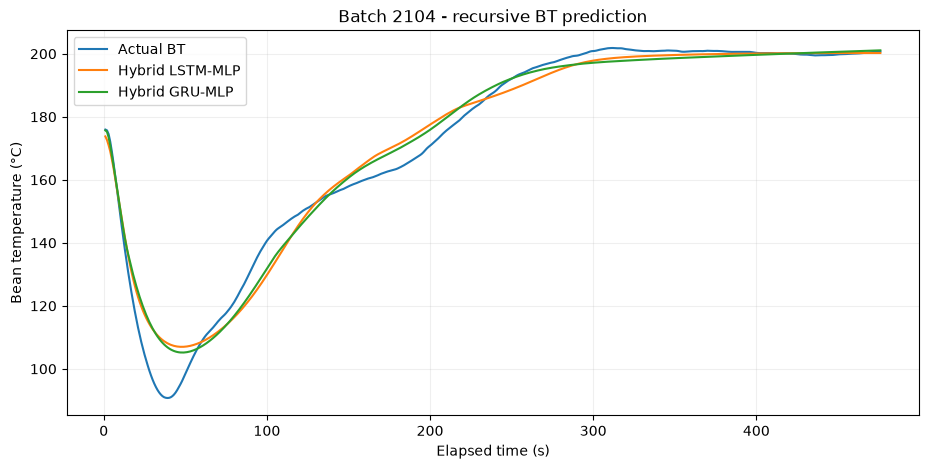

In [19]:
import matplotlib.pyplot as plt
batch_id=2104
s=next(s for s in test_samples if s['batch_id']==batch_id)
y,p_lstm=predict_test_roast(lstm,s,'LSTM')
_,p_gru=predict_test_roast(gru,s,'GRU')
seconds=s['X_seq'][:,0]
plt.figure(figsize=(11,5))
plt.plot(seconds,y,label='Actual BT')
plt.plot(seconds,p_lstm,label='Hybrid LSTM-MLP')
plt.plot(seconds,p_gru,label='Hybrid GRU-MLP')
plt.xlabel('Elapsed time (s)');plt.ylabel('Bean temperature (°C)')
plt.title(f'Batch {batch_id} - recursive BT prediction')
plt.legend();plt.grid(alpha=0.2);plt.show()

## 11. Use GRU-MLP with PSO and the DSS without touching the LSTM version

The companion `dss_backend_gru.py` loads your new `hybrid_gru_random_search_best.pt`. Its PSO still optimizes **airflow 50–100%** and **planned development 30–90 s**, with the original 20 particles / 30 iterations and the existing objective (profile MSE + change penalty + duration penalty). It uses the same ROEST target profile and the same four static inputs. `app_gru.py` is a separate Streamlit interface for GRU.

After the saved GRU checkpoint exists, copy both files into `ROEST_Thesis/` and run in a terminal:

```bash
cd ROEST_Thesis
pip install streamlit pyswarms torch pandas numpy scikit-learn joblib matplotlib
streamlit run app_gru.py
```

The original `streamlit run app.py` remains the LSTM-based DSS. Compare the two systems on **the same roast(s), random seeds, PSO budget, target profile and fitness terms**; do not claim that a lower *model-predicted* error confirms a physically better roast. When computing GRU vs LSTM **optimization** quality, each model assesses its own suggested trajectories; their predicted improvements are not independent ground truth. Physical validation is needed to confirm real next-roast improvement.

## 12. Interpretation for your thesis

Update the predictive-model baseline in **Chapter 3, Section 3.2.11** and **Chapter 4, Sections 4.4–4.5** to describe the GRU-MLP comparison. Keep the original Standard LSTM comparison as a *secondary* experiment if useful, and clearly separate it from the fair hybrid-vs-hybrid test. State whether GRU-MLP or LSTM-MLP has lower test RMSE, whether the paired Wilcoxon test finds a significant difference, and the trade-off between runtime/model complexity and temperature accuracy. Retain PSO-vs-Random-Search as a separate optimization comparison. Do **not** replace old reported results until you run full training and check the new outputs.